# 00.5 · The whole course in one notebook

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/00-big-picture/05-whole-course-in-one-notebook/lesson.ipynb)

**Do not try to understand the code.** You will, lesson by lesson, over the next eleven modules. Today you are a passenger: run every cell, read the short text above each, and watch the seven steps happen on real data. Every section says which module teaches it properly.

The data is ShopWave's real transaction history (Online Retail II, 2010–2011): about 540,000 rows.

## Step 1 · Frame

| | |
|---|---|
| Decision | Marketing sends a voucher to customers likely to churn; also wants customer segments and a sales forecast |
| Unit | One customer, as of the **cut-off date 2011-09-09** (90 days before the data ends) |
| Target | `churned` = 1 if the customer placed **no order in the 90 days after the cut-off** |
| Features | Built only from orders **before** the cut-off: recency, frequency, monetary value, and more |
| Baseline | "flag anyone with no order in the 60 days before the cut-off" |

## Step 2 · Get the data

Downloads once (about 45 MB), then reads the 2010–2011 sheet. *Module 01 teaches Pandas.*

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, time
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

t0 = time.time()
raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(f"loaded {len(raw):,} rows in {time.time() - t0:.0f}s")
raw.head()

loaded 541,910 rows in 13s


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Step 3 · Explore and clean

Remove cancellations, guest checkouts and bad prices; add an `amount` column; look at one chart. *Module 01 teaches exploratory data analysis properly.*

397,885 clean rows, 4,338 customers, 2010-12-01 to 2011-12-09


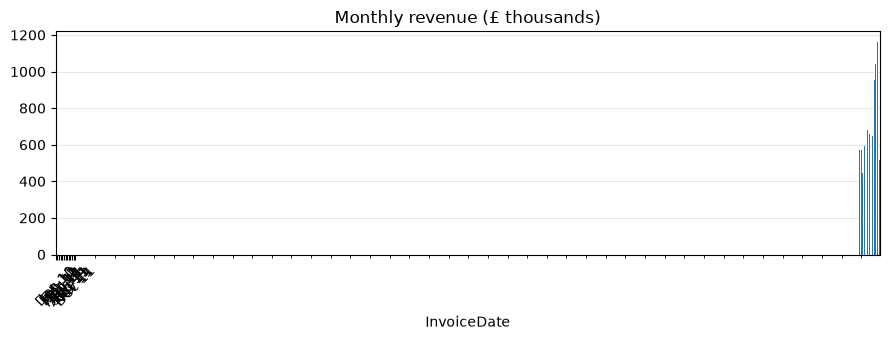

In [2]:
df = raw.dropna(subset=["Customer ID"]).copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
df = df[~df["Invoice"].astype(str).str.startswith("C")]
df["amount"] = df["Quantity"] * df["Price"]
df["Customer ID"] = df["Customer ID"].astype(int)
print(f"{len(df):,} clean rows, {df['Customer ID'].nunique():,} customers, "
      f"{df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}")

monthly = df.set_index("InvoiceDate")["amount"].resample("ME").sum() / 1e3
monthly.plot(kind="bar", figsize=(9, 3.5), title="Monthly revenue (£ thousands)", color="tab:blue")
plt.xticks(range(len(monthly)), [d.strftime("%b %y") for d in monthly.index], rotation=45)
plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

## Step 4 · Prepare: build the customer table

One row per customer, features from **before** the cut-off, label from **after** it. The features are the classic **RFM** trio: *Recency* (days since last order), *Frequency* (number of orders), *Monetary* (total spent), plus a few more. *Modules 01 and 04 teach feature engineering.*

In [3]:
cutoff = pd.Timestamp("2011-09-09")
before = df[df["InvoiceDate"] < cutoff]
after = df[df["InvoiceDate"] >= cutoff]

g = before.groupby("Customer ID")
customers = pd.DataFrame({
    "recency_days":   (cutoff - g["InvoiceDate"].max()).dt.days,
    "frequency":      g["Invoice"].nunique(),
    "monetary":       g["amount"].sum().round(2),
    "avg_basket":     (g["amount"].sum() / g["Invoice"].nunique()).round(2),
    "n_products":     g["StockCode"].nunique(),
    "tenure_days":    (cutoff - g["InvoiceDate"].min()).dt.days,
    "is_uk":          (g["Country"].first() == "United Kingdom").astype(int),
})
customers["churned"] = (~customers.index.isin(after["Customer ID"].unique())).astype(int)

print(f"{len(customers):,} customers; churn rate {customers['churned'].mean():.1%}")
customers.head()

3,362 customers; churn rate 42.9%


,recency_days,frequency,monetary,avg_basket,n_products,tenure_days,is_uk,churned
Customer ID,,,,,,,,
12346,233,1,77183.60,77183.60,1,233,1,1
12347,37,5,2790.86,558.17,82,275,0,0
12348,156,3,1487.24,495.75,22,266,0,0
12350,218,1,334.40,334.40,17,218,0,1
12352,170,5,1561.81,312.36,26,204,0,0


## Step 4 (continued) · Split

Hold back 25% of customers. The model never sees them until Step 6. *Module 04.*

In [4]:
from sklearn.model_selection import train_test_split

features = ["recency_days", "frequency", "monetary", "avg_basket", "n_products", "tenure_days", "is_uk"]
X, y = customers[features], customers["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"train {len(X_train):,}  test {len(X_test):,}")

train 2,521  test 841


## Step 5 · Model: a Random Forest

Hundreds of decision trees voting. *Module 03 teaches classification; Module 05 teaches ensembles like this one.*

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print("trained", rf.n_estimators, "trees")

trained 300 trees


## Step 6 · Evaluate

Accuracy on unseen customers, against the baseline, plus the **confusion matrix**: how many churners we caught and how many loyal customers we would bother with a voucher. *Module 03 teaches these metrics.*

baseline accuracy: 61.5%
forest   accuracy: 66.2%


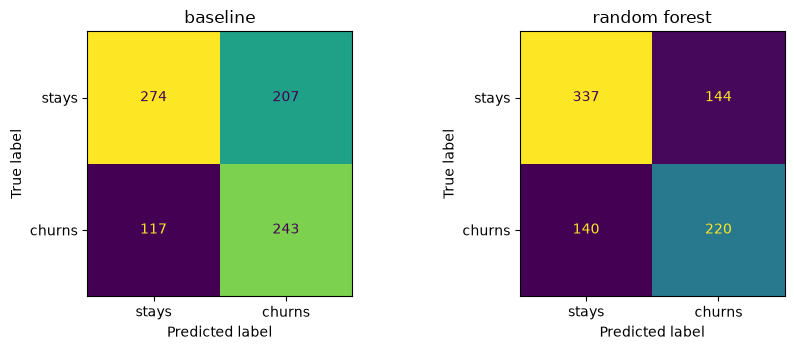

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

baseline_pred = (X_test["recency_days"] > 60).astype(int)
rf_pred = rf.predict(X_test)

print(f"baseline accuracy: {accuracy_score(y_test, baseline_pred):.1%}")
print(f"forest   accuracy: {accuracy_score(y_test, rf_pred):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, pred, title in [(axes[0], baseline_pred, "baseline"), (axes[1], rf_pred, "random forest")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["stays", "churns"]).plot(ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

Read each square: rows are the truth, columns are the prediction. Top-right = loyal customers we would wrongly send a voucher to; bottom-left = churners we miss.

## Step 6 (continued) · Explain

Which features did the forest rely on? *Module 05 teaches explainability (and SHAP, which is better than this).*

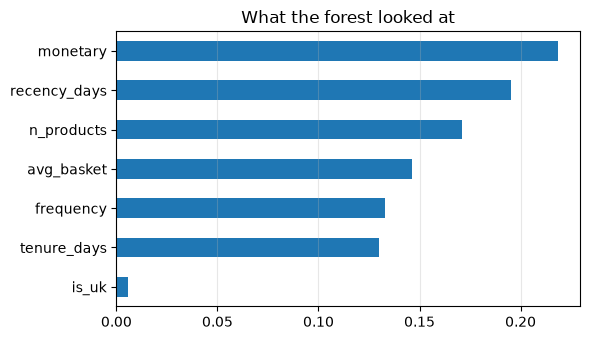

In [7]:
importance = pd.Series(rf.feature_importances_, index=features).sort_values()
importance.plot.barh(figsize=(6, 3.5), title="What the forest looked at", color="tab:blue")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

## Unsupervised detour · Customer segments

No label this time. K-Means groups customers by recency, frequency and monetary value; we then describe each group. *Module 06.*

In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

rfm = customers[["recency_days", "frequency", "monetary"]]
rfm_scaled = StandardScaler().fit_transform(np.log1p(rfm))       # log tames the long tail of big spenders
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(rfm_scaled)
customers["segment"] = km.labels_

profile = customers.groupby("segment").agg(customers=("churned", "size"),
                                           recency_days=("recency_days", "median"),
                                           orders=("frequency", "median"),
                                           spent=("monetary", "median"),
                                           churn_rate=("churned", "mean")).round(2)
profile

,customers,recency_days,orders,spent,churn_rate
segment,,,,,
0,507,9.0,9.0,3079.38,0.10
1,1565,148.0,1.0,257.68,0.61
2,1290,45.0,3.0,918.98,0.33


Name the groups yourself from the table: one is probably "loyal big spenders", one "occasional", one "lapsed". The churn rate per segment is the sanity check: segments built without the label should still differ on it.

## Forecasting detour · Next month's sales

The simplest possible forecast, a seasonal naive one: "next month will be like the same month last year, scaled by this year's growth". *Module 07 does this properly with ARIMA and ML.*

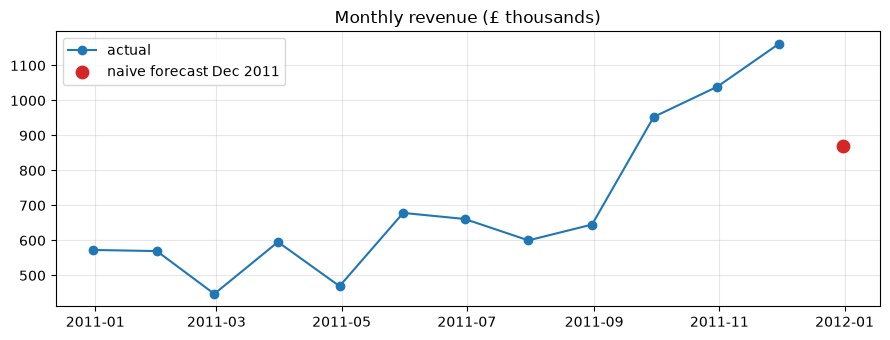

naive forecast for December 2011: £870k


In [9]:
m = df.set_index("InvoiceDate")["amount"].resample("ME").sum() / 1e3
m = m[m.index < "2011-12-01"]                                   # last month is partial; drop it

hist = m["2010-12":"2011-11"]
growth = hist["2011-06":"2011-11"].sum() / m["2010-12":"2011-05"].sum()   # crude growth ratio
forecast_dec = m["2010-12-31"] * growth

plt.figure(figsize=(9, 3.5))
plt.plot(hist.index, hist.values, marker="o", label="actual")
plt.scatter([pd.Timestamp("2011-12-31")], [forecast_dec], color="tab:red", s=80, zorder=5, label="naive forecast Dec 2011")
plt.title("Monthly revenue (£ thousands)"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print(f"naive forecast for December 2011: £{forecast_dec:,.0f}k")

## Step 7 · Deploy

Save the trained forest to a file, load it as a different program would, and predict for one new customer. *Module 10 wraps this in an API and a web app, and adds monitoring.*

In [10]:
import joblib
joblib.dump(rf, "churn_forest.joblib")
served = joblib.load("churn_forest.joblib")

new_customer = pd.DataFrame([{"recency_days": 75, "frequency": 3, "monetary": 420.0, "avg_basket": 140.0,
                              "n_products": 25, "tenure_days": 300, "is_uk": 1}])
p = served.predict_proba(new_customer)[0, 1]
print(f"churn probability for the new customer: {p:.0%}  ->  {'send voucher' if p > 0.5 else 'no action'}")

churn probability for the new customer: 53%  ->  send voucher


## What you just did

| Step | Module that teaches it |
|---|---|
| Loaded and cleaned 540k rows | 01 |
| Charted monthly revenue | 01 |
| Built RFM features and a churn label with a cut-off date | 01, 04 |
| Split train / test | 04 |
| Trained a random forest | 03, 05 |
| Accuracy, confusion matrix, baseline | 03 |
| Feature importance | 05 |
| K-Means segments | 06 |
| Naive forecast | 07 |
| Saved and served the model | 10 |

Not in this notebook, but in the course: neural networks and images (08), text and language models (09), and the capstone (11).

## Quiz answers

1. 2011-09-09: 90 days before the data ends, so the label can be computed from the 90 days after it.
2. The baseline flags anyone with no order in the previous 60 days. It is a single rule and needs no model.
3. Rows are the truth, columns the prediction. Top-right counts loyal customers wrongly predicted to churn.
4. Total spend and recency come top, with number of products close behind; country (`is_uk`) is almost ignored. No single feature dominates, which is why the forest only beats the recency-only baseline by a few points.
5. K-Means. It received no label; the churn rate per segment was computed afterwards as a sanity check.

**Next:** [Module 01 · Working with Data](../../01-working-with-data/). Everything above started with loading, cleaning and summarising a table. That is where the real course begins.